In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Customer_ID": [
        "C001", "C002", "C003", "C004", "C005",
        "C006", "C007", "C008", "C009", "C010",
        "C011", "C012", "C013", "C014", "C015"
    ],

    "Age": [
        21, 25, 32, 28, 41,
        23, 35, 30, 45, 27,
        38, 22, 33, 29, 40
    ],

    "Gender": [
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male"
    ],

    "Total_Spending": [
        450, 720, 1200, 650, 1500,
        380, 980, 830, 1750, 540,
        1100, 420, 890, 760, 1350
    ],

    "Purchases": [
        2, 4, 6, 3, 7,
        2, 5, 4, 8, 3,
        6, 2, 5, 4, 7
    ]
}

df = pd.DataFrame(data)

df

,Customer_ID,Age,Gender,Total_Spending,Purchases
0,C001,21,Male,450,2
1,C002,25,Female,720,4
2,C003,32,Male,1200,6
3,C004,28,Female,650,3
4,C005,41,Male,1500,7
5,C006,23,Female,380,2
6,C007,35,Male,980,5
7,C008,30,Female,830,4
8,C009,45,Male,1750,8
9,C010,27,Female,540,3


In [2]:
print("===== CUSTOMER ANALYSIS =====")

print("Number of Customers:", df["Customer_ID"].nunique())

print("Average Age:", round(df["Age"].mean(), 2))

print("Total Spending:", df["Total_Spending"].sum())

print("Average Spending:", round(df["Total_Spending"].mean(), 2))

print("Total Purchases:", df["Purchases"].sum())

===== CUSTOMER ANALYSIS =====
Number of Customers: 15
Average Age: 31.27
Total Spending: 13520
Average Spending: 901.33
Total Purchases: 68


In [4]:
top_customers = (
    df[["Customer_ID", "Total_Spending"]]
    .sort_values("Total_Spending", ascending=False)
)

print(top_customers)

   Customer_ID  Total_Spending
8         C009            1750
4         C005            1500
14        C015            1350
2         C003            1200
10        C011            1100
6         C007             980
12        C013             890
7         C008             830
13        C014             760
1         C002             720
3         C004             650
9         C010             540
0         C001             450
11        C012             420
5         C006             380


In [5]:
top_5 = top_customers.head(5)

print("===== TOP 5 CUSTOMERS =====")
print(top_5)

===== TOP 5 CUSTOMERS =====
   Customer_ID  Total_Spending
8         C009            1750
4         C005            1500
14        C015            1350
2         C003            1200
10        C011            1100


In [6]:
gender_spending = (
    df.groupby("Gender")["Total_Spending"]
    .sum()
    .sort_values(ascending=False)
)

print("===== SPENDING BY GENDER =====")
print(gender_spending)

===== SPENDING BY GENDER =====
Gender
Male      9220
Female    4300
Name: Total_Spending, dtype: int64


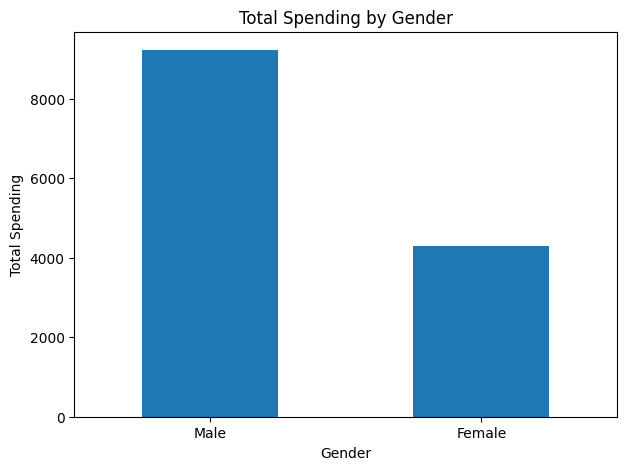

In [7]:
gender_spending.plot(
    kind="bar",
    figsize=(7, 5),
    title="Total Spending by Gender"
)

plt.xlabel("Gender")
plt.ylabel("Total Spending")
plt.xticks(rotation=0)
plt.show()

In [8]:
bins = [0, 24, 34, 44, 100]

labels = [
    "18-24",
    "25-34",
    "35-44",
    "45+"
]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels
)

df[["Customer_ID", "Age", "Age_Group"]]

,Customer_ID,Age,Age_Group
0,C001,21,18-24
1,C002,25,25-34
2,C003,32,25-34
3,C004,28,25-34
4,C005,41,35-44
5,C006,23,18-24
6,C007,35,35-44
7,C008,30,25-34
8,C009,45,45+
9,C010,27,25-34


In [9]:
age_spending = (
    df.groupby("Age_Group", observed=True)["Total_Spending"]
    .sum()
)

print("===== SPENDING BY AGE GROUP =====")
print(age_spending)

===== SPENDING BY AGE GROUP =====
Age_Group
18-24    1250
25-34    5590
35-44    4930
45+      1750
Name: Total_Spending, dtype: int64


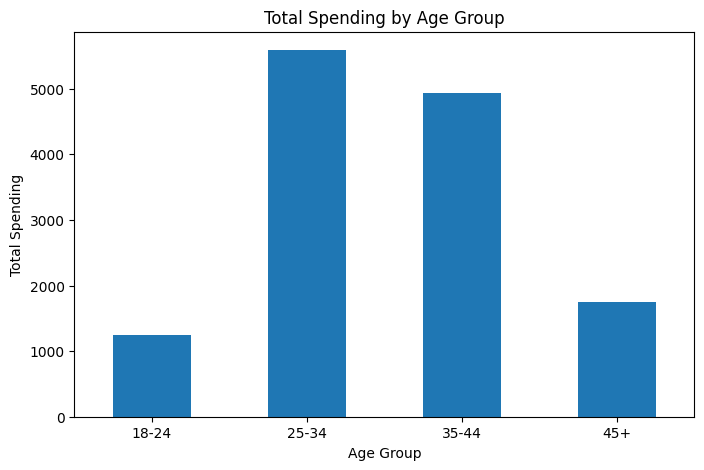

In [10]:
age_spending.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Spending by Age Group"
)

plt.xlabel("Age Group")
plt.ylabel("Total Spending")
plt.xticks(rotation=0)
plt.show()

In [11]:
purchase_rank = (
    df[["Customer_ID", "Purchases"]]
    .sort_values("Purchases", ascending=False)
)

print("===== TOP CUSTOMERS BY PURCHASES =====")
print(purchase_rank.head(5))

===== TOP CUSTOMERS BY PURCHASES =====
   Customer_ID  Purchases
8         C009          8
14        C015          7
4         C005          7
2         C003          6
10        C011          6


In [12]:
best_spender = df.loc[
    df["Total_Spending"].idxmax(),
    "Customer_ID"
]

highest_spending = df["Total_Spending"].max()

best_gender = gender_spending.idxmax()

best_age_group = age_spending.idxmax()

most_frequent_customer = df.loc[
    df["Purchases"].idxmax(),
    "Customer_ID"
]

print("===== BUSINESS INSIGHTS =====")

print(f"1. Highest-spending customer: {best_spender}")
print(f"   Spending: {highest_spending}")

print(f"2. Highest-spending gender group: {best_gender}")

print(f"3. Highest-spending age group: {best_age_group}")

print(f"4. Customer with most purchases: {most_frequent_customer}")

===== BUSINESS INSIGHTS =====
1. Highest-spending customer: C009
   Spending: 1750
2. Highest-spending gender group: Male
3. Highest-spending age group: 25-34
4. Customer with most purchases: C009
